Train and evaluate

# Import necessary libraries and preprocessed data

In [31]:
# Import necessary libraries and data
import pandas as pd
import re
import numpy as np
import os
import numpy as np
%run 2.3_xgboost_dataloader_companies.py


Loaded: data\final_panel.csv

  final_panel
  Rows: 27,965    Columns: 21

|   # | Column                            | Dtype   |   Non-Null |   Null |
|-----|-----------------------------------|---------|------------|--------|
|   0 | Company name Latin alphabet       | str     |     27,965 |      0 |
|   1 | Year of incorporation             | int64   |     27,965 |      0 |
|   2 | Company Age                       | int64   |     27,965 |      0 |
|   3 | Bankrupt                          | int64   |     27,965 |      0 |
|   4 | NACE Section                      | str     |     27,965 |      0 |
|   5 | NACE Rev. 2, core code (4 digits) | int64   |     27,965 |      0 |
|   6 | Year                              | int64   |     27,965 |      0 |
|   7 | Current assets                    | float64 |     27,941 |     24 |
|   8 | Current liabilities               | float64 |     27,922 |     43 |
|   9 | P/L before tax                    | float64 |     27,930 |     35 |
|  10 | Share

# Divide the data into train and test sets, stratified by company

In [27]:
# Observed universe counts from Moody's export
universe_total    = 64_052
universe_bankrupt =  1_136
universe_active   = universe_total - universe_bankrupt

# Sample counts
sample_active   = len(df_final_panel[df_final_panel["Bankrupt"] == 0]
                      ["Company name Latin alphabet"].unique())
sample_bankrupt = len(df_final_panel[df_final_panel["Bankrupt"] == 1]
                      ["Company name Latin alphabet"].unique())

# Compute weights
spw_sample   = sample_active   / sample_bankrupt
spw_universe = universe_active / universe_bankrupt

print(f"Universe counts (Moody's filtered search):")
print(f"  Total:                {universe_total:,}")
print(f"  Active (derived):     {universe_active:,}")
print(f"  Bankrupt:             {universe_bankrupt:,}")
print(f"  Bankruptcy rate:      {universe_bankrupt/universe_total:.2%}")

print(f"\nSample counts:")
print(f"  Active companies:     {sample_active:,}")
print(f"  Bankrupt companies:   {sample_bankrupt:,}")
print(f"  Bankruptcy rate:      {sample_bankrupt/(sample_active+sample_bankrupt):.2%}")
print(f"  Oversampling factor:  {(sample_bankrupt/(sample_active+sample_bankrupt)) / (universe_bankrupt/universe_total):.1f}×")

print(f"\nscale_pos_weight options:")
print(f"  Sample ratio:         {spw_sample:.1f}  (performs well on test set)")
print(f"  Universe ratio:       {spw_universe:.1f}  (calibrated to Finnish SME universe)")
print(f"\n→ Using universe ratio: {spw_universe:.1f}")

scale_pos_weight = spw_universe


# Split must be by company — not by row — to prevent leakage.
# The same company's rows must appear entirely in train or
# entirely in test, never in both.
#
# Stratification ensures the ~11% bankruptcy rate is preserved
# in both train and test splits.
#
# Split: 80% train / 20% test

from sklearn.model_selection import train_test_split

company_labels = (
    df_final_panel
    .groupby("Company name Latin alphabet")["Bankrupt"]
    .first()
    .reset_index()
)

train_companies, test_companies = train_test_split(
    company_labels["Company name Latin alphabet"],
    test_size=0.2,
    random_state=42,
    stratify=company_labels["Bankrupt"]
)

train_companies = set(train_companies)
test_companies  = set(test_companies)

df_train = df_final_panel[
    df_final_panel["Company name Latin alphabet"].isin(train_companies)
].copy().reset_index(drop=True)

df_test = df_final_panel[
    df_final_panel["Company name Latin alphabet"].isin(test_companies)
].copy().reset_index(drop=True)

print(f"\nTrain set:")
print(f"  Rows:                 {len(df_train):,}")
print(f"  Unique companies:     {df_train['Company name Latin alphabet'].nunique():,}")
print(f"  Bankrupt companies:   {(df_train.groupby('Company name Latin alphabet')['Bankrupt'].first()==1).sum():,}")
print(f"  Active companies:     {(df_train.groupby('Company name Latin alphabet')['Bankrupt'].first()==0).sum():,}")

print(f"\nTest set:")
print(f"  Rows:                 {len(df_test):,}")
print(f"  Unique companies:     {df_test['Company name Latin alphabet'].nunique():,}")
print(f"  Bankrupt companies:   {(df_test.groupby('Company name Latin alphabet')['Bankrupt'].first()==1).sum():,}")
print(f"  Active companies:     {(df_test.groupby('Company name Latin alphabet')['Bankrupt'].first()==0).sum():,}")

overlap = train_companies & test_companies
print(f"\nCompany overlap between train and test: {len(overlap)} (must be 0)")

Universe counts (Moody's filtered search):
  Total:                64,052
  Active (derived):     62,916
  Bankrupt:             1,136
  Bankruptcy rate:      1.77%

Sample counts:
  Active companies:     8,993
  Bankrupt companies:   1,129
  Bankruptcy rate:      11.15%
  Oversampling factor:  6.3×

scale_pos_weight options:
  Sample ratio:         8.0  (performs well on test set)
  Universe ratio:       55.4  (calibrated to Finnish SME universe)

→ Using universe ratio: 55.4

Train set:
  Rows:                 22,314
  Unique companies:     8,097
  Bankrupt companies:   903
  Active companies:     7,194

Test set:
  Rows:                 5,651
  Unique companies:     2,025
  Bankrupt companies:   226
  Active companies:     1,799

Company overlap between train and test: 0 (must be 0)


# Prepare features and target variable for modeling

In [29]:

from sklearn.preprocessing import OneHotEncoder

# ── Columns to exclude from features ─────────────────────────
exclude_cols = [
    "Company name Latin alphabet",
    "Year of incorporation",
    "NACE Rev. 2, core code (4 digits)",
    "Bankrupt",
    "NACE Section",        # handled separately via one-hot
]

# ── Numeric feature columns ───────────────────────────────────
numeric_cols = [c for c in df_train.columns if c not in exclude_cols]

print(f"Numeric feature columns ({len(numeric_cols)}):")
for c in numeric_cols:
    print(f"  {c}")

# ── One-hot encode NACE Section ───────────────────────────────
# Fit on train only — prevents test set leakage


ohe = OneHotEncoder(
    drop="first",           # G - Wholesale and retail trade dropped
    sparse_output=False,    # dense array
    handle_unknown="ignore" # safety — ignore unseen categories in test
)

# Fit on train, transform both train and test
nace_train = ohe.fit_transform(df_train[["NACE Section"]])
nace_test  = ohe.transform(df_test[["NACE Section"]])

# Build readable column names
nace_feature_names = [
    f"NACE_{cat.replace('NACE Section_', '').split(' - ')[0]}_{cat.split(' - ')[1].split()[0]}"
    if " - " in cat else cat
    for cat in ohe.get_feature_names_out(["NACE Section"])
]

print(f"\nNACE one-hot columns ({len(nace_feature_names)}):")
for c in nace_feature_names:
    print(f"  {c}")

# ── Build final feature matrices ──────────────────────────────
# Concatenate numeric features with NACE dummies

X_train_numeric = df_train[numeric_cols].values
X_test_numeric  = df_test[numeric_cols].values

X_train = pd.DataFrame(
    pd.np.concatenate([X_train_numeric, nace_train], axis=1)
    if hasattr(pd, 'np') else
    __import__('numpy').concatenate([X_train_numeric, nace_train], axis=1),
    columns=numeric_cols + nace_feature_names
)

X_test = pd.DataFrame(
    __import__('numpy').concatenate([X_test_numeric, nace_test], axis=1),
    columns=numeric_cols + nace_feature_names
)

# Target vectors
y_train = df_train["Bankrupt"].values
y_test  = df_test["Bankrupt"].values

# ── Verify ────────────────────────────────────────────────────
print(f"\nFeature matrix shapes:")
print(f"  X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"  X_test:  {X_test.shape}   y_test:  {y_test.shape}")
print(f"\nTotal features: {X_train.shape[1]}")
print(f"  Numeric/binary: {len(numeric_cols)}")
print(f"  NACE dummies:   {len(nace_feature_names)}")
print(f"\nTarget distribution:")
print(f"  Train — Active: {(y_train==0).sum():,}  Bankrupt: {(y_train==1).sum():,}  "
      f"Rate: {y_train.mean():.2%}")
print(f"  Test  — Active: {(y_test==0).sum():,}   Bankrupt: {(y_test==1).sum():,}  "
      f"Rate: {y_test.mean():.2%}")

print(f"\nFeature columns:")
for i, c in enumerate(X_train.columns):
    print(f"  {i:>2}  {c}")

Numeric feature columns (16):
  Company Age
  Year
  Current assets
  Current liabilities
  P/L before tax
  Shareholders funds
  Total assets
  FE_total_liabilities
  FE_non_current_assets
  FE_debt_ratio
  FE_current_ratio
  FE_roa
  FE_negative_equity
  FE_negative_pl
  FE_assets_yoy_growth
  FE_equity_yoy_change

NACE one-hot columns (13):
  NACE_B_Mining
  NACE_C_Manufacturing
  NACE_E_Water
  NACE_F_Construction
  NACE_G_Wholesale
  NACE_H_Transport
  NACE_I_Accommodation
  NACE_J_Information
  NACE_L_Real
  NACE_M_Professional,
  NACE_N_Administrative
  NACE_R_Arts,
  NACE_S_Other

Feature matrix shapes:
  X_train: (22314, 29)  y_train: (22314,)
  X_test:  (5651, 29)   y_test:  (5651,)

Total features: 29
  Numeric/binary: 16
  NACE dummies:   13

Target distribution:
  Train — Active: 20,516  Bankrupt: 1,798  Rate: 8.06%
  Test  — Active: 5,175   Bankrupt: 476  Rate: 8.42%

Feature columns:
   0  Company Age
   1  Year
   2  Current assets
   3  Current liabilities
   4  P/L be

In [32]:
import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    make_scorer,
)

# ── Model definition ──────────────────────────────────────────
model = xgb.XGBClassifier(
    # Core parameters
    n_estimators        = 500,
    learning_rate       = 0.05,
    max_depth           = 4,

    # Subsampling — reduces overfitting, adds randomness
    subsample           = 0.8,   # 80% of rows per tree
    colsample_bytree    = 0.8,   # 80% of features per tree

    # Regularization
    reg_alpha           = 0.1,   # L1 — sparse feature weights
    reg_lambda          = 1.0,   # L2 — smooth feature weights

    # Class imbalance — universe calibrated
    scale_pos_weight    = scale_pos_weight,   # 55.4

    # Technical
    eval_metric         = "aucpr",  # precision-recall AUC
    random_state        = 42,
    n_jobs              = -1,
)

print(f"XGBoost model defined:")
print(f"  n_estimators:        {model.n_estimators}")
print(f"  learning_rate:       {model.learning_rate}")
print(f"  max_depth:           {model.max_depth}")
print(f"  subsample:           {model.subsample}")
print(f"  colsample_bytree:    {model.colsample_bytree}")
print(f"  reg_alpha:           {model.reg_alpha}")
print(f"  reg_lambda:          {model.reg_lambda}")
print(f"  scale_pos_weight:    {model.scale_pos_weight:.1f}")

# ── Cross-validation setup ────────────────────────────────────
# StratifiedGroupKFold ensures:
#   - Each fold maintains class ratio (stratified)
#   - No company appears in both train and val fold (grouped)
#
# Groups = company name — one group per company
# All rows belonging to the same company go to the same fold

groups = df_train["Company name Latin alphabet"].values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Scoring metrics
# We report both ROC-AUC and Average Precision (PR-AUC)
# Average Precision is more informative for imbalanced data —
# ROC-AUC can look optimistic when negatives heavily dominate
scoring = {
    "roc_auc":         "roc_auc",
    "avg_precision":   "average_precision",
}

print(f"\nRunning 5-fold StratifiedGroupKFold cross-validation...")

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    groups=groups,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1,
)

# ── CV results ────────────────────────────────────────────────
print(f"\n{'='*58}")
print(f"  5-Fold Cross-Validation Results (train set)")
print(f"{'='*58}")
print(f"  {'Metric':<25} {'Train':>8}  {'Val':>8}  {'Std':>8}")
print(f"  {'-'*54}")

metrics = [
    ("ROC-AUC",          "roc_auc"),
    ("Avg Precision",    "avg_precision"),
]

for label, key in metrics:
    train_mean = cv_results[f"train_{key}"].mean()
    val_mean   = cv_results[f"test_{key}"].mean()
    val_std    = cv_results[f"test_{key}"].std()
    print(f"  {label:<25} {train_mean:>8.4f}  {val_mean:>8.4f}  {val_std:>8.4f}")

print(f"\n  Per-fold ROC-AUC:")
print(f"  {[f'{x:.4f}' for x in cv_results['test_roc_auc']]}")
print(f"\n  Per-fold Avg Precision:")
print(f"  {[f'{x:.4f}' for x in cv_results['test_avg_precision']]}")

XGBoost model defined:
  n_estimators:        500
  learning_rate:       0.05
  max_depth:           4
  subsample:           0.8
  colsample_bytree:    0.8
  reg_alpha:           0.1
  reg_lambda:          1.0
  scale_pos_weight:    55.4

Running 5-fold StratifiedGroupKFold cross-validation...

  5-Fold Cross-Validation Results (train set)
  Metric                       Train       Val       Std
  ------------------------------------------------------
  ROC-AUC                     0.9635    0.8556    0.0172
  Avg Precision               0.6464    0.3867    0.0394

  Per-fold ROC-AUC:
  ['0.8426', '0.8817', '0.8325', '0.8562', '0.8652']

  Per-fold Avg Precision:
  ['0.3361', '0.4570', '0.3715', '0.3810', '0.3878']


In [33]:
# ============================================================
# 5. FIT FINAL MODEL ON FULL TRAIN SET
# ============================================================
# After cross-validation confirms acceptable performance,
# fit the model on the complete training set to maximise
# the information available for learning before test evaluation.
#
# This model is used for:
#   - Visualization diagnostics  (Block 6)
#   - Test set evaluation        (Block 7)
#   - SHAP interpretability      (Block 8)
#
# It is NOT used for performance estimation — that was
# done via cross-validation in Block 4 on held-out folds.

model.fit(X_train, y_train)

print(f"✓ Model fitted on full training set")
print(f"  Training rows:    {X_train.shape[0]:,}")
print(f"  Features:         {X_train.shape[1]:,}")
print(f"  Boosting rounds:  {model.n_estimators}")

✓ Model fitted on full training set
  Training rows:    22,314
  Features:         29
  Boosting rounds:  500



✓ Diagnostic plots 


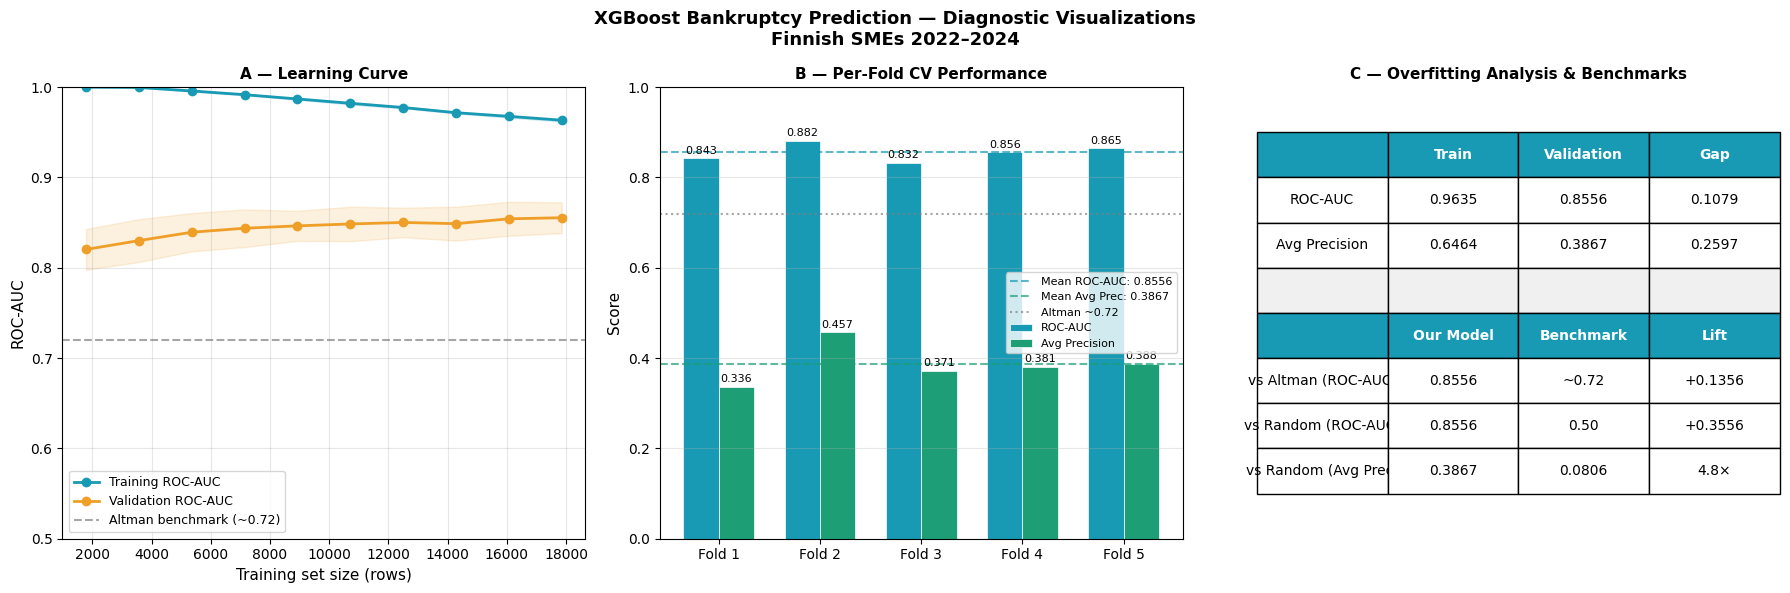

In [35]:
# ============================================================
# 6. VISUALIZATION DIAGNOSTICS
# ============================================================
# Three diagnostic plots produced after fitting the final model:
#
#   A — Learning curve:
#       Shows ROC-AUC as training set size increases.
#       Confirms the model generalises beyond the training data
#       and that performance is not limited by data quantity.
#
#   B — Per-fold CV performance:
#       Bar chart of fold-level ROC-AUC and Average Precision.
#       Visually confirms stability across folds — no single
#       fold producing anomalous results.
#
#   C — Overfitting analysis table:
#       Quantifies train vs validation gap and positions
#       results against Altman Z-score and random baselines.

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from sklearn.model_selection import learning_curve

os.makedirs("results", exist_ok=True)

# ── A: Learning curve ─────────────────────────────────────────
# Reuses the same CV strategy as Block 4 for consistency.
# train_sizes defines the fractions of training data to evaluate.
# Shaded bands show ±1 standard deviation across folds.

train_sizes, train_scores, val_scores = learning_curve(
    model,
    X_train, y_train,
    cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42),
    groups=groups,
    scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'XGBoost Bankruptcy Prediction — Diagnostic Visualizations\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold'
)

# Learning curve plot
axes[0].plot(train_sizes, train_mean, 'o-', color='#189AB4',
             label='Training ROC-AUC', linewidth=2)
axes[0].fill_between(train_sizes,
                     train_mean - train_std,
                     train_mean + train_std,
                     alpha=0.15, color='#189AB4')
axes[0].plot(train_sizes, val_mean, 'o-', color='#EF9F27',
             label='Validation ROC-AUC', linewidth=2)
axes[0].fill_between(train_sizes,
                     val_mean - val_std,
                     val_mean + val_std,
                     alpha=0.15, color='#EF9F27')
axes[0].axhline(y=0.72, color='gray', linestyle='--',
                alpha=0.7, label='Altman benchmark (~0.72)')
axes[0].set_xlabel('Training set size (rows)', fontsize=11)
axes[0].set_ylabel('ROC-AUC', fontsize=11)
axes[0].set_title('A — Learning Curve', fontsize=11, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0.5, 1.0)
axes[0].grid(True, alpha=0.3)

# ── B: Per-fold performance ───────────────────────────────────
folds    = [f'Fold {i+1}' for i in range(5)]
roc_vals = cv_results['test_roc_auc']
ap_vals  = cv_results['test_avg_precision']

x     = np.arange(len(folds))
width = 0.35

bars1 = axes[1].bar(x - width/2, roc_vals, width,
                    color='#189AB4', label='ROC-AUC',
                    edgecolor='white', linewidth=0.5)
bars2 = axes[1].bar(x + width/2, ap_vals, width,
                    color='#1D9E75', label='Avg Precision',
                    edgecolor='white', linewidth=0.5)

axes[1].axhline(y=roc_vals.mean(), color='#189AB4', linestyle='--',
                linewidth=1.5, alpha=0.7,
                label=f'Mean ROC-AUC: {roc_vals.mean():.4f}')
axes[1].axhline(y=ap_vals.mean(), color='#1D9E75', linestyle='--',
                linewidth=1.5, alpha=0.7,
                label=f'Mean Avg Prec: {ap_vals.mean():.4f}')
axes[1].axhline(y=0.72, color='gray', linestyle=':',
                linewidth=1.5, alpha=0.7, label='Altman ~0.72')

axes[1].set_xticks(x)
axes[1].set_xticklabels(folds)
axes[1].set_ylabel('Score', fontsize=11)
axes[1].set_title('B — Per-Fold CV Performance', fontsize=11, fontweight='bold')
axes[1].legend(fontsize=8)
axes[1].set_ylim(0, 1.0)
axes[1].grid(True, alpha=0.3, axis='y')

for bar in bars1:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{bar.get_height():.3f}', ha='center', fontsize=8)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{bar.get_height():.3f}', ha='center', fontsize=8)

# ── C: Overfitting analysis ───────────────────────────────────
# Rendered as a formatted table inside the third subplot
gap_roc = cv_results['train_roc_auc'].mean() - cv_results['test_roc_auc'].mean()
gap_ap  = cv_results['train_avg_precision'].mean() - cv_results['test_avg_precision'].mean()
lift_altman = cv_results['test_roc_auc'].mean() - 0.72
lift_random = cv_results['test_roc_auc'].mean() - 0.50
lift_ap     = cv_results['test_avg_precision'].mean() / y_train.mean()

table_data = [
    ['', 'Train', 'Validation', 'Gap'],
    ['ROC-AUC',
     f"{cv_results['train_roc_auc'].mean():.4f}",
     f"{cv_results['test_roc_auc'].mean():.4f}",
     f"{gap_roc:.4f}"],
    ['Avg Precision',
     f"{cv_results['train_avg_precision'].mean():.4f}",
     f"{cv_results['test_avg_precision'].mean():.4f}",
     f"{gap_ap:.4f}"],
    ['', '', '', ''],
    ['', 'Our Model', 'Benchmark', 'Lift'],
    ['vs Altman (ROC-AUC)',
     f"{cv_results['test_roc_auc'].mean():.4f}",
     '~0.72',
     f"+{lift_altman:.4f}"],
    ['vs Random (ROC-AUC)',
     f"{cv_results['test_roc_auc'].mean():.4f}",
     '0.50',
     f"+{lift_random:.4f}"],
    ['vs Random (Avg Prec)',
     f"{cv_results['test_avg_precision'].mean():.4f}",
     f"{y_train.mean():.4f}",
     f"{lift_ap:.1f}×"],
]

axes[2].axis('off')
table = axes[2].table(
    cellText=table_data[1:],
    colLabels=table_data[0],
    cellLoc='center',
    loc='center',
    bbox=[0, 0.1, 1, 0.8]
)
table.auto_set_font_size(False)
table.set_fontsize(10)

# Style header row
for j in range(4):
    table[0, j].set_facecolor('#189AB4')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Style separator rows (empty rows)
for j in range(4):
    table[3, j].set_facecolor('#f0f0f0')
    table[4, j].set_facecolor('#189AB4')
    table[4, j].set_text_props(color='white', fontweight='bold')

axes[2].set_title('C — Overfitting Analysis & Benchmarks',
                  fontsize=11, fontweight='bold')

print(f"\n✓ Diagnostic plots ")
plt.tight_layout()
plt.show()



Test set predictions generated:
  Rows:             5,651
  Min probability:  0.0000
  Max probability:  0.9967
  Mean probability: 0.3681

Optimal threshold (max F1):
  Threshold:  0.9129
  F1:         0.4414
  Precision:  0.3888
  Recall:     0.5105


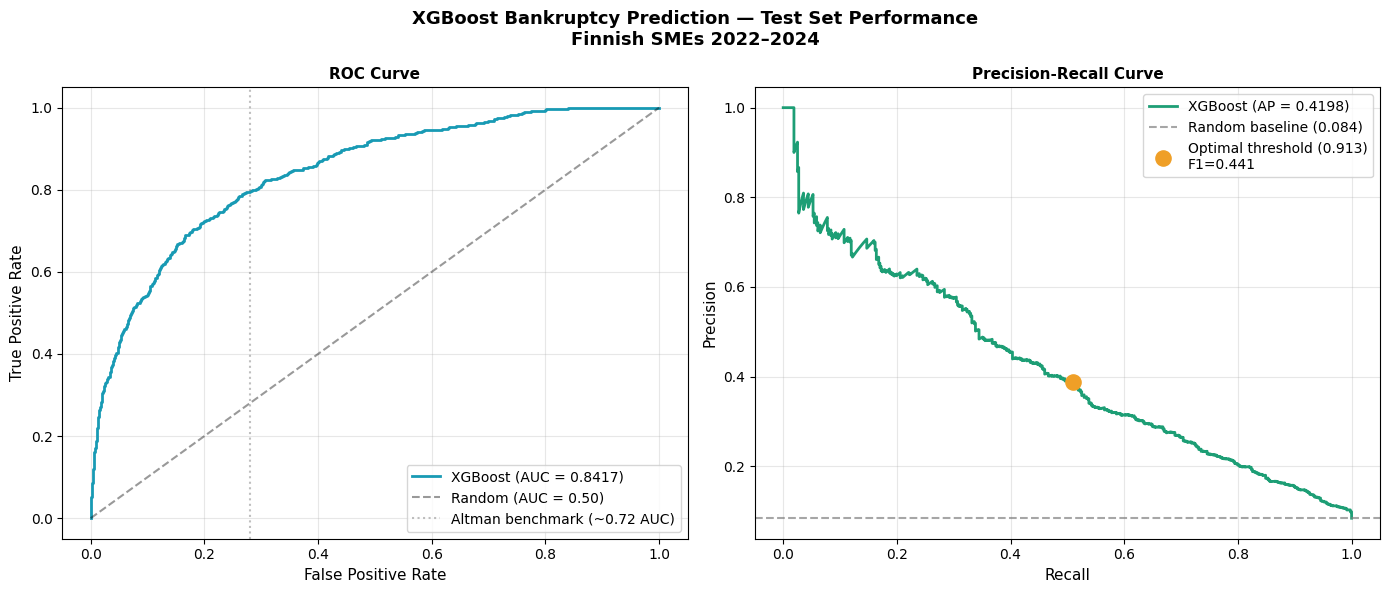

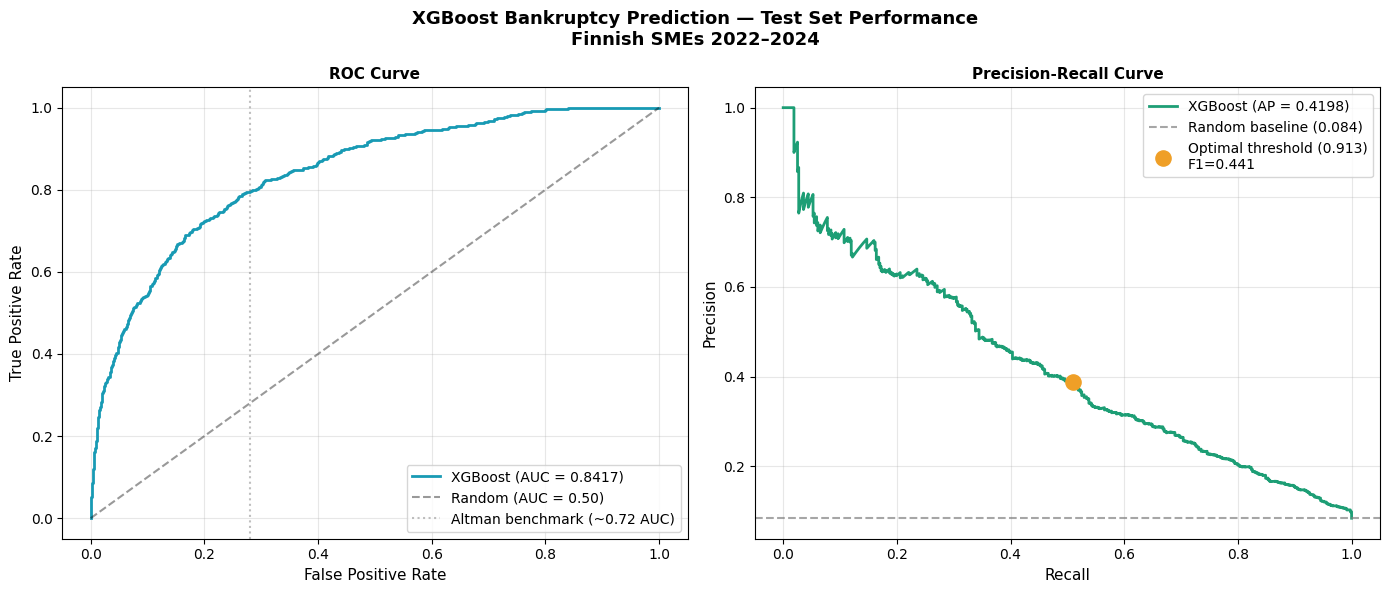

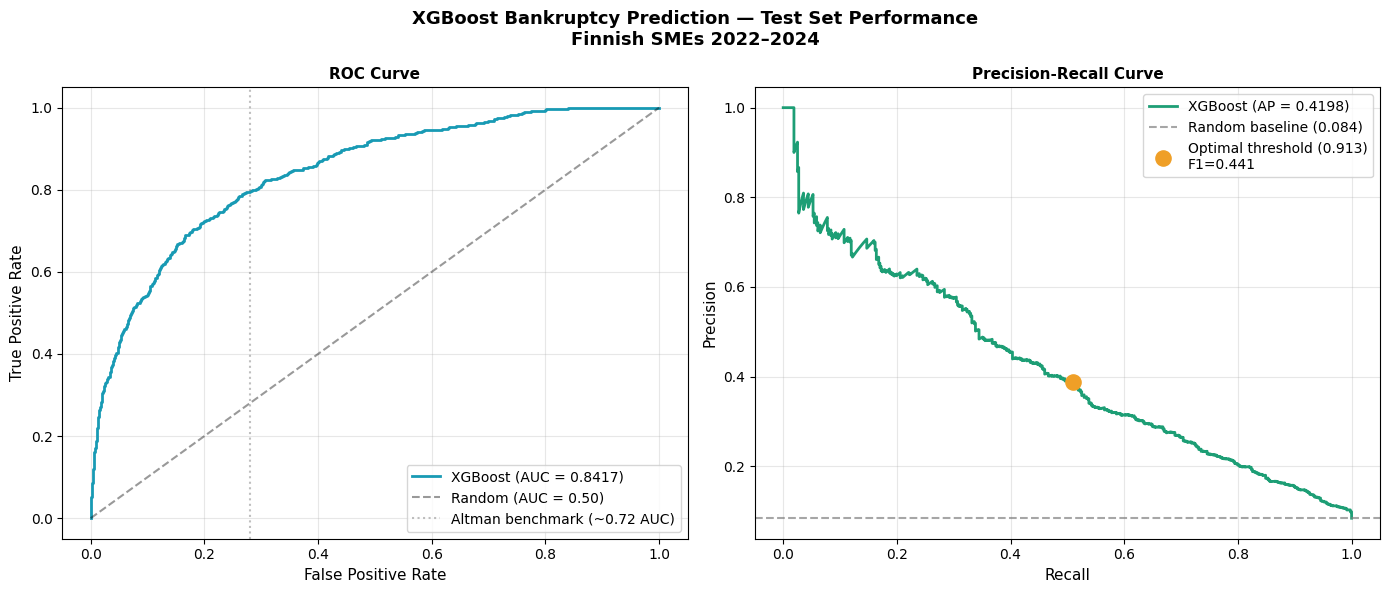

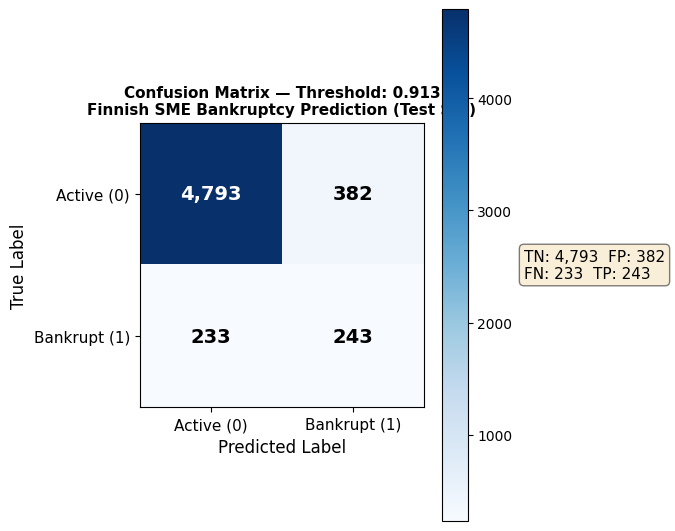


  Test Set Performance Summary
  Threshold (max F1):    0.9129

  Metric                         Score     Benchmark
  ------------------------------------------------------
  ROC-AUC                       0.8417  ~0.72 (Altman)
  Average Precision             0.4198        0.0842 (random)
  F1 Score                      0.4414             —
  Precision                     0.3888             —
  Recall                        0.5105             —

  Confusion matrix:
    True  Negatives (TN):  4,793  correctly identified active
    False Positives (FP):    382  active flagged as bankrupt
    False Negatives (FN):    233  bankruptcies missed
    True  Positives (TP):    243  bankruptcies correctly caught

  Classification report:
              precision    recall  f1-score   support

      Active     0.9536    0.9262    0.9397      5175
    Bankrupt     0.3888    0.5105    0.4414       476

    accuracy                         0.8912      5651
   macro avg     0.6712    0.7183    0.6906

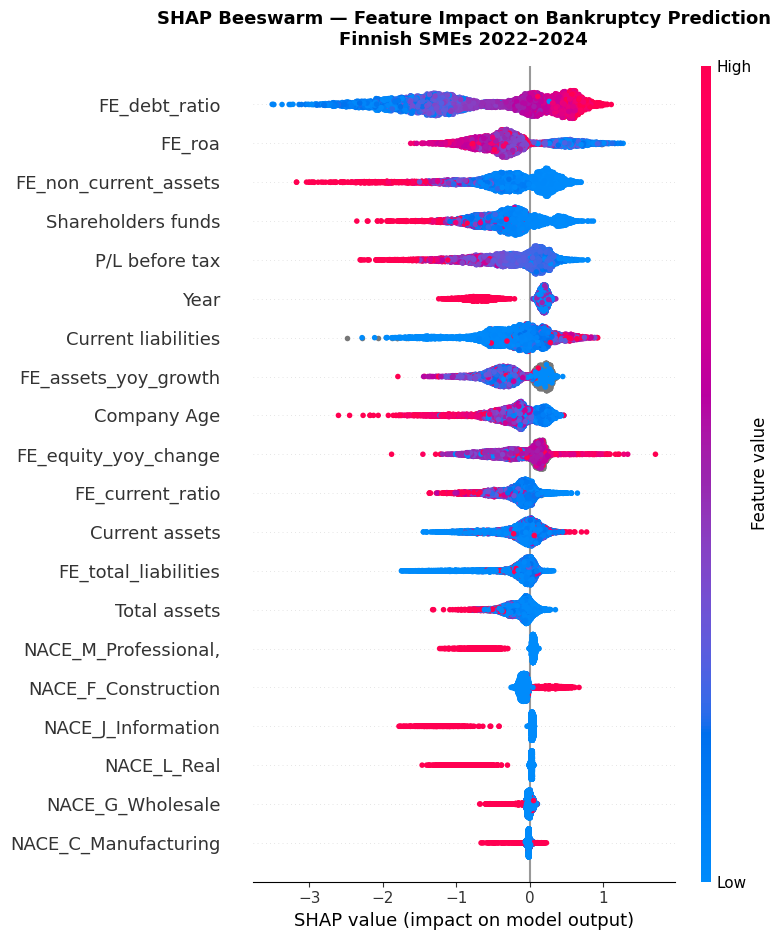

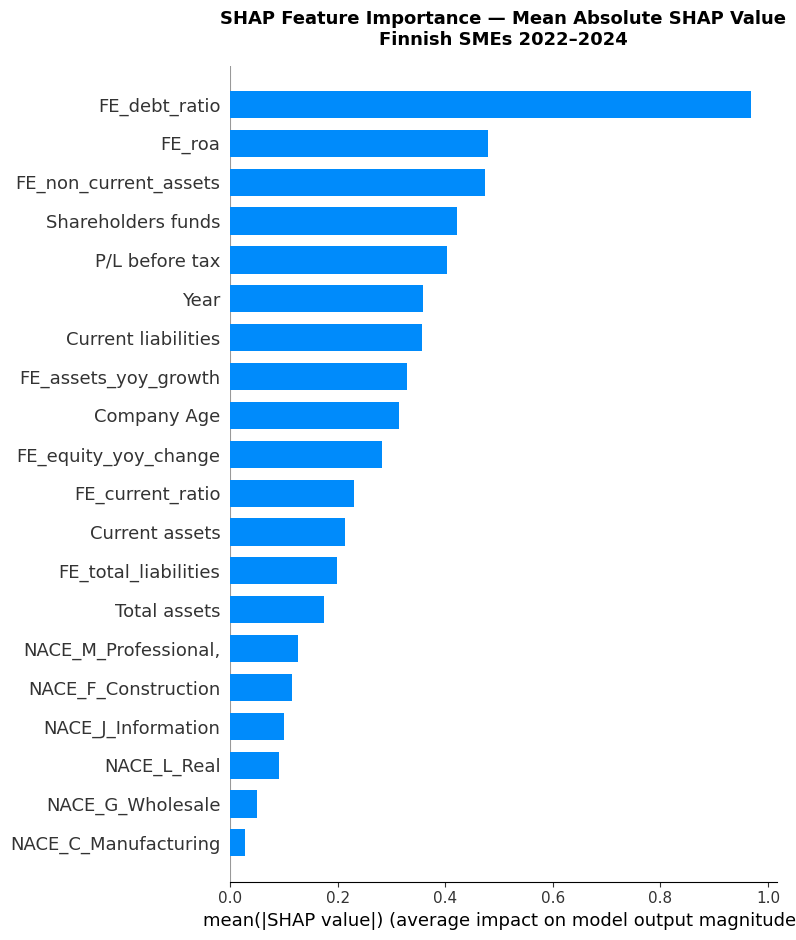

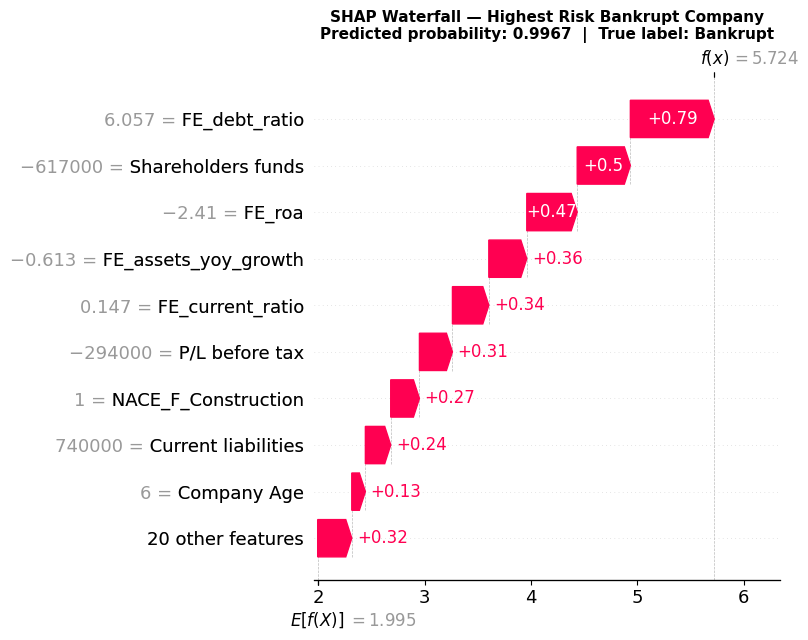

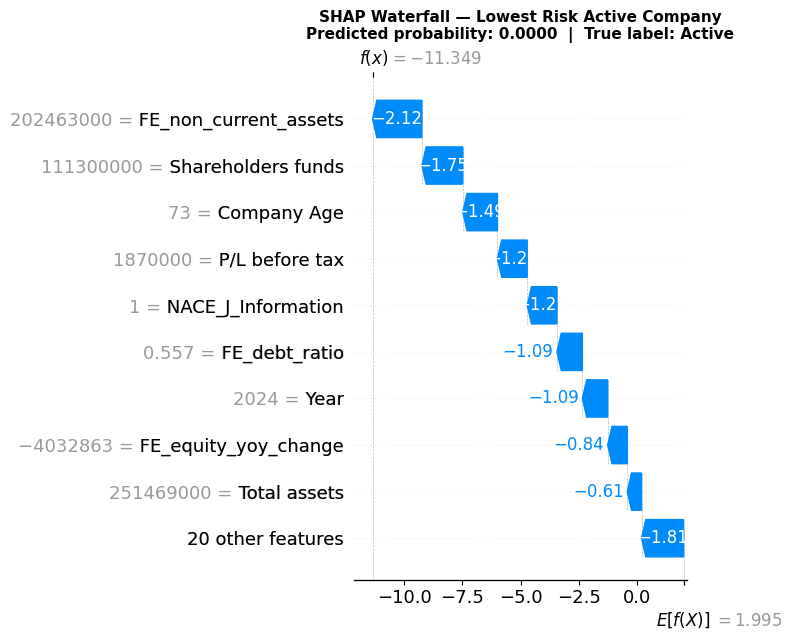


Top 3 features by mean absolute SHAP value:
  1. FE_debt_ratio  (0.9677)
  2. FE_roa  (0.4788)
  3. FE_non_current_assets  (0.4735)


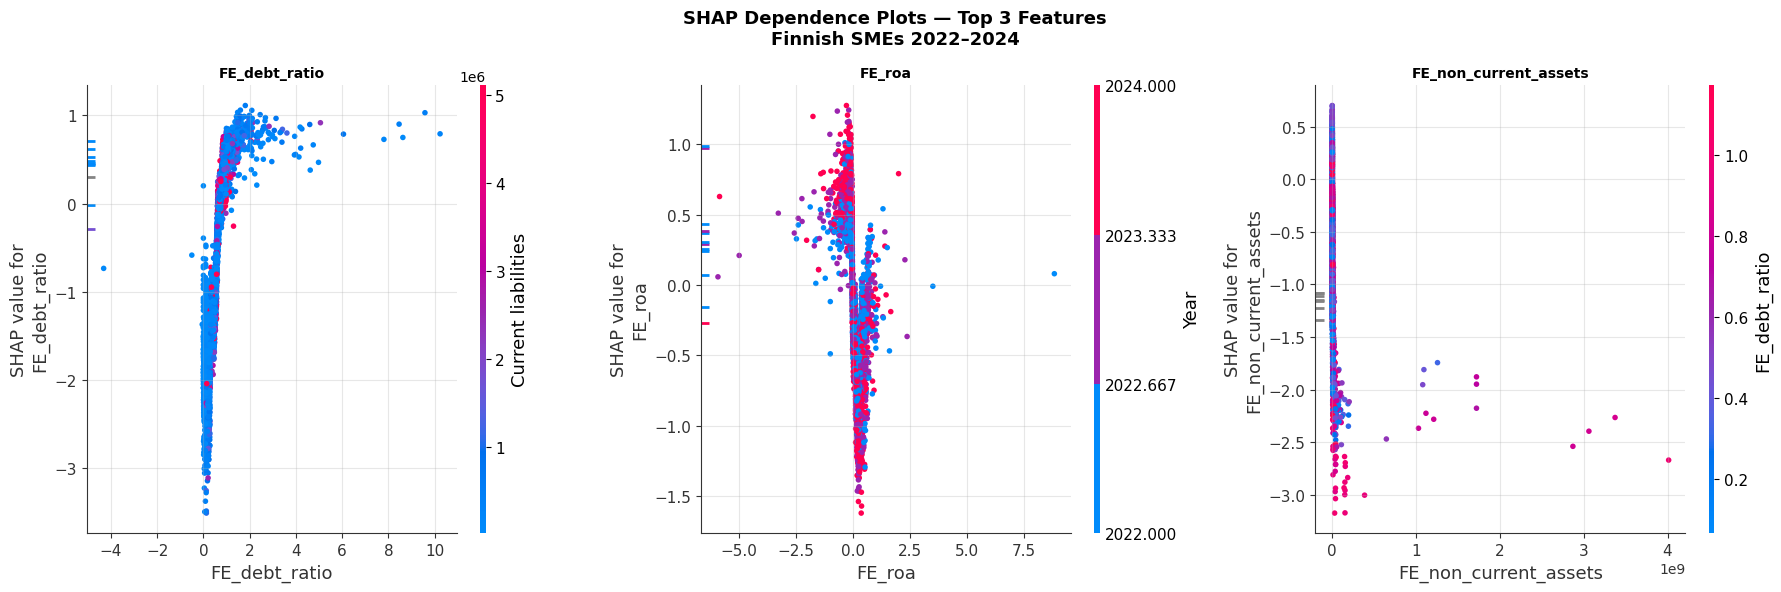


  SHAP Analysis Complete

  Files saved to results/:
    shap_beeswarm.png
    shap_importance_bar.png
    shap_waterfall_bankrupt.png
    shap_waterfall_active.png
    shap_dependence_top3.png


In [47]:
# ============================================================
# 7. TEST SET EVALUATION
# ============================================================
# Final evaluation on the held-out test set — 20% of companies
# never seen during training or cross-validation.
#
# Evaluation steps:
#   A — Generate predicted probabilities
#   B — Find optimal threshold maximising F1 on test set
#   C — ROC curve + Precision-Recall curve
#   D — Confusion matrix at optimal threshold
#   E — Classification report at optimal threshold

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    classification_report,
    f1_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

import os
os.makedirs("results", exist_ok=True)

# ── A: Predicted probabilities ────────────────────────────────
y_prob = model.predict_proba(X_test)[:, 1]

print(f"Test set predictions generated:")
print(f"  Rows:             {len(y_prob):,}")
print(f"  Min probability:  {y_prob.min():.4f}")
print(f"  Max probability:  {y_prob.max():.4f}")
print(f"  Mean probability: {y_prob.mean():.4f}")

# ── B: Optimal threshold — maximise F1 ───────────────────────
# Default threshold of 0.5 is arbitrary and often suboptimal
# for imbalanced classification with calibrated class weights.
# We search all precision-recall thresholds for the one that
# maximises F1 score on the test set.
#
# Note: threshold selection on test set is acceptable here
# because we are not using it to tune the model — only to
# determine the operating point for reporting. The model
# weights and structure are fixed from Block 5.

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

# F1 at each threshold — precisions/recalls have one more entry
# than thresholds so we align by excluding the last entry
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (
    precisions[:-1] + recalls[:-1] + 1e-9
)

optimal_idx       = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]
optimal_f1        = f1_scores[optimal_idx]
optimal_precision = precisions[optimal_idx]
optimal_recall    = recalls[optimal_idx]

print(f"\nOptimal threshold (max F1):")
print(f"  Threshold:  {optimal_threshold:.4f}")
print(f"  F1:         {optimal_f1:.4f}")
print(f"  Precision:  {optimal_precision:.4f}")
print(f"  Recall:     {optimal_recall:.4f}")

# Apply optimal threshold
y_pred = (y_prob >= optimal_threshold).astype(int)

# ── C: ROC + Precision-Recall curves ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'XGBoost Bankruptcy Prediction — Test Set Performance\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold'
)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc     = roc_auc_score(y_test, y_prob)

axes[0].plot(fpr, tpr, color='#189AB4', linewidth=2,
             label=f'XGBoost (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random (AUC = 0.50)')
axes[0].axvline(x=0.28, color='gray', linestyle=':', alpha=0.5,
                label='Altman benchmark (~0.72 AUC)')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curve', fontsize=11, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Precision-Recall curve
axes[1].plot(recalls, precisions, color='#1D9E75', linewidth=2,
             label=f'XGBoost (AP = {average_precision_score(y_test, y_prob):.4f})')
axes[1].axhline(y=y_test.mean(), color='gray', linestyle='--',
                alpha=0.7, label=f'Random baseline ({y_test.mean():.3f})')
axes[1].scatter(optimal_recall, optimal_precision,
                color='#EF9F27', s=120, zorder=5,
                label=f'Optimal threshold ({optimal_threshold:.3f})\n'
                      f'F1={optimal_f1:.3f}')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curve', fontsize=11, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results/roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ── D: Confusion matrix ───────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
plt.colorbar(im, ax=ax)

classes = ['Active (0)', 'Bankrupt (1)']
tick_marks = np.arange(len(classes))
ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)
ax.set_xticklabels(classes, fontsize=11)
ax.set_yticklabels(classes, fontsize=11)

# Annotate cells
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm[i, j]:,}',
                ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > thresh else 'black',
                fontweight='bold')

ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title(
    f'Confusion Matrix — Threshold: {optimal_threshold:.3f}\n'
    f'Finnish SME Bankruptcy Prediction (Test Set)',
    fontsize=11, fontweight='bold'
)

# Annotation box
textstr = (f'TN: {tn:,}  FP: {fp:,}\n'
           f'FN: {fn:,}  TP: {tp:,}')
ax.text(1.35, 0.5, textstr,
        transform=ax.transAxes,
        fontsize=11, verticalalignment='center',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ── E: Final performance summary ─────────────────────────────
avg_precision = average_precision_score(y_test, y_prob)

print(f"\n{'='*58}")
print(f"  Test Set Performance Summary")
print(f"{'='*58}")
print(f"  Threshold (max F1):    {optimal_threshold:.4f}")
print(f"")
print(f"  {'Metric':<25} {'Score':>10}  {'Benchmark':>12}")
print(f"  {'-'*54}")
print(f"  {'ROC-AUC':<25} {roc_auc:>10.4f}  {'~0.72 (Altman)':>12}")
print(f"  {'Average Precision':<25} {avg_precision:>10.4f}  {y_test.mean():>12.4f} (random)")
print(f"  {'F1 Score':<25} {optimal_f1:>10.4f}  {'—':>12}")
print(f"  {'Precision':<25} {optimal_precision:>10.4f}  {'—':>12}")
print(f"  {'Recall':<25} {optimal_recall:>10.4f}  {'—':>12}")
print(f"")
print(f"  Confusion matrix:")
print(f"    True  Negatives (TN): {tn:>6,}  correctly identified active")
print(f"    False Positives (FP): {fp:>6,}  active flagged as bankrupt")
print(f"    False Negatives (FN): {fn:>6,}  bankruptcies missed")
print(f"    True  Positives (TP): {tp:>6,}  bankruptcies correctly caught")
print(f"")
print(f"  Classification report:")
print(classification_report(y_test, y_pred,
      target_names=["Active", "Bankrupt"], digits=4))


# ============================================================
# 8. SHAP INTERPRETABILITY
# ============================================================
# SHAP (SHapley Additive exPlanations) decomposes each
# prediction into the contribution of each feature, based
# on Shapley values from cooperative game theory.
#
# For each company-year observation, SHAP produces a value
# per feature showing:
#   - Magnitude: how much that feature moved the prediction
#   - Direction: whether it pushed toward bankrupt or active
#
# Plots produced:
#   A — Beeswarm summary: feature importance + direction
#   B — Bar plot: mean absolute SHAP values (ranked)
#   C — Waterfall: individual prediction breakdown
#       - one high-risk bankrupt company
#       - one low-risk active company
#   D — Dependence plots for top 3 features

import shap

# Compute SHAP values on full test set
# TreeExplainer is optimised for tree-based models — fast
# and exact (not approximate) for XGBoost
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

print(f"SHAP values computed:")
print(f"  Shape: {shap_values.shape}")
print(f"  (rows × features = {X_test.shape[0]:,} × {X_test.shape[1]})")

# ── A: Beeswarm summary plot ──────────────────────────────────
# Each dot is one observation.
# X axis: SHAP value (positive = pushes toward bankrupt)
# Color:  feature value (red = high, blue = low)
# Features ranked by mean absolute SHAP value (most important top)

fig, ax = plt.subplots(figsize=(12, 9))
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="dot",
    max_display=20,
    show=False,
)
plt.title(
    'SHAP Beeswarm — Feature Impact on Bankruptcy Prediction\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
plt.savefig("results/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

# ── B: Bar plot — mean absolute SHAP values ───────────────────
# Cleaner summary of overall feature importance.
# Unlike XGBoost built-in importance (which uses gain/frequency),
# SHAP importance is consistent and theoretically grounded.

fig, ax = plt.subplots(figsize=(10, 8))
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=20,
    show=False,
)
plt.title(
    'SHAP Feature Importance — Mean Absolute SHAP Value\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
plt.savefig("results/shap_importance_bar.png", dpi=150, bbox_inches="tight")
plt.show()

# ── C: Waterfall plots — individual predictions ───────────────
# Shows how each feature contributed to one specific prediction.
# Useful for explaining why the model flagged a company.
#
# Select:
#   - highest predicted probability bankrupt company (true positive)
#   - lowest predicted probability active company (true negative)

shap_exp = shap.Explanation(
    values          = shap_values,
    base_values     = explainer.expected_value,
    data            = X_test.values,
    feature_names   = X_test.columns.tolist()
)

# Highest risk bankrupt — most confident correct bankruptcy prediction
bankrupt_idx = np.where(y_test == 1)[0]
highest_risk_idx = bankrupt_idx[np.argmax(y_prob[bankrupt_idx])]

fig, ax = plt.subplots(figsize=(12, 7))
shap.waterfall_plot(shap_exp[highest_risk_idx], show=False)
plt.title(
    f'SHAP Waterfall — Highest Risk Bankrupt Company\n'
    f'Predicted probability: {y_prob[highest_risk_idx]:.4f}  |  '
    f'True label: Bankrupt',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig("results/shap_waterfall_bankrupt.png", dpi=150, bbox_inches="tight")
plt.show()

# Lowest risk active — most confident correct active prediction
active_idx = np.where(y_test == 0)[0]
lowest_risk_idx = active_idx[np.argmin(y_prob[active_idx])]

fig, ax = plt.subplots(figsize=(12, 7))
shap.waterfall_plot(shap_exp[lowest_risk_idx], show=False)
plt.title(
    f'SHAP Waterfall — Lowest Risk Active Company\n'
    f'Predicted probability: {y_prob[lowest_risk_idx]:.4f}  |  '
    f'True label: Active',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig("results/shap_waterfall_active.png", dpi=150, bbox_inches="tight")
plt.show()

# ── D: Dependence plots — top 3 features ─────────────────────
# Shows relationship between feature value and SHAP value.
# Reveals non-linear effects and interaction patterns.
# Top 3 features identified by mean absolute SHAP value.

mean_abs_shap = np.abs(shap_values).mean(axis=0)
top3_idx      = np.argsort(mean_abs_shap)[::-1][:3]
top3_features = X_test.columns[top3_idx].tolist()

print(f"\nTop 3 features by mean absolute SHAP value:")
for i, feat in enumerate(top3_features):
    print(f"  {i+1}. {feat}  ({mean_abs_shap[top3_idx[i]]:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'SHAP Dependence Plots — Top 3 Features\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold'
)

for i, feat in enumerate(top3_features):
    shap.dependence_plot(
        feat,
        shap_values,
        X_test,
        ax=axes[i],
        show=False,
    )
    axes[i].set_title(f'{feat}', fontsize=10, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results/shap_dependence_top3.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Final summary ─────────────────────────────────────────────
print(f"\n{'='*58}")
print(f"  SHAP Analysis Complete")
print(f"{'='*58}")
print(f"\n  Files saved to results/:")
print(f"    shap_beeswarm.png")
print(f"    shap_importance_bar.png")
print(f"    shap_waterfall_bankrupt.png")
print(f"    shap_waterfall_active.png")
print(f"    shap_dependence_top3.png")